In [ ]:
# If using Google Colab runtime and Google Drive to Store Data
from google.colab import drive
drive.mount('/content/drive')

#Select the directory where raw data were uploaded
base_dir = ""

Mounted at /content/drive


In [ ]:
import pandas as pd
import os
import gc
import pickle
import numpy as np

import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error,mean_squared_error, r2_score

# Preprocessing

##Import, Merge, and Clean Data
Import data from data.police.uk, merge the raw datasets, remove duplicates, drop missing values

In [ ]:
data_dir = os.path.join(base_dir, "raw_crime_data")
files = os.listdir(data_dir)

# join the data from all the raw street data files
df = pd.concat([pd.read_csv(os.path.join(data_dir, file)) for file in files])

no_records = len(df)

# drop duplicates
df = df.drop_duplicates()

duplicates_dropped = no_records - len(df)
no_records = len(df)

# drop missing LSOA code, month, crime type
df = df.dropna(subset=['LSOA code', 'Month', 'Crime type'])

empty_dropped = no_records - len(df)
no_records = len(df)

# write data to csv
csv_out_path = os.path.join(base_dir, 'clean_data', 'cleaned.csv')
df.to_csv(csv_out_path, index=False)

# display head and stats
print("Duplicates: %d, Empty Values: %d, Remaining Records: %d" % (duplicates_dropped, empty_dropped, no_records))
display(df.head())

del df
gc.collect();



Duplicates: 2565351, Empty Values: 158094, Remaining Records: 14245882


,Crime ID,Month,Reported by,Falls within,Longitude,Latitude,Location,LSOA code,LSOA name,Crime type,Last outcome category,Context
0,NaN,2011-08,Metropolitan Police Service,Metropolitan Police Service,0.134947,51.588063,On or near Mead Grove,E01000027,Barking and Dagenham 001A,Anti-social behaviour,NaN,NaN
1,NaN,2011-08,Metropolitan Police Service,Metropolitan Police Service,0.133166,51.586720,On or near Rosehatch Avenue,E01000027,Barking and Dagenham 001A,Anti-social behaviour,NaN,NaN
3,NaN,2011-08,Metropolitan Police Service,Metropolitan Police Service,0.140192,51.582311,On or near Hatch Grove,E01000027,Barking and Dagenham 001A,Anti-social behaviour,NaN,NaN
4,NaN,2011-08,Metropolitan Police Service,Metropolitan Police Service,0.141561,51.589642,On or near Kingston Hill Avenue,E01000027,Barking and Dagenham 001A,Anti-social behaviour,NaN,NaN
9,NaN,2011-08,Metropolitan Police Service,Metropolitan Police Service,0.136466,51.587514,On or near Gibbfield Close,E01000027,Barking and Dagenham 001A,Anti-social behaviour,NaN,NaN


##Aggregate Data
Aggregate the data, counting the number of occurences of each crime, grouped by (LSOA, Date, Crime Type)-combinations

In [ ]:
# load data
csv_in_path = os.path.join(base_dir, 'clean_data', 'cleaned.csv')
df = pd.read_csv(csv_in_path, usecols=['Month', 'LSOA code', 'Crime type'])

# Group by counts
counts = df.groupby(['Month', 'LSOA code', 'Crime type']).size().reset_index(name='Count')


# Create all possible Month, LSOA, Crime Type combinations
all_combinations = pd.MultiIndex.from_product(
    [
    df['Month'].unique(),
    df['LSOA code'].unique(),
    df['Crime type'].unique(),
    ],
    names = ['Month', 'LSOA code', 'Crime type']
    ).to_frame(index=False)

# loaded data no longer needed
del df
gc.collect()

# create new data frame
df = all_combinations.merge(counts, on=['Month', 'LSOA code', 'Crime type'], how='left').fillna({'Count':0})

# Two parts no longer needed
del all_combinations
del counts
gc.collect()

# write csv
csv_out_path = os.path.join(base_dir, 'clean_data', 'aggregated.csv')
df.to_csv(csv_out_path, index=False)

# head to display
print('Aggregated dataset length:', len(df))
display(df.head())

del df
gc.collect();

Aggregated dataset length: 50236608


,Month,LSOA code,Crime type,Count
0,2011-08,E01000027,Anti-social behaviour,7.0
1,2011-08,E01000027,Burglary,2.0
2,2011-08,E01000027,Vehicle crime,2.0
3,2011-08,E01000027,Violent crime,3.0
4,2011-08,E01000027,Other crime,4.0


## Feature Encoding
Encode the features:
*   Month -> Year, Month column
*   LSOA -> X,Y coordinate of the population weighted centroid
*   Crime type -> using 1-hot encoding



In [ ]:
# csv file to read from
csv_in_path = os.path.join(base_dir, 'clean_data', 'aggregated.csv')
df = pd.read_csv(csv_in_path)

# Encode year and month as two integers
df["Month"] = pd.to_datetime(df["Month"])
df['Year'] = df['Month'].dt.year.astype('int16')
df['Month'] = df['Month'].dt.month.astype('int8')

# One-Hot Encode
df = pd.get_dummies(df, columns=['Crime type'], prefix="", prefix_sep="")

# Save dataframe length
pre_LSOA_lookup = len(df)

# LSOA lookup table load
csv_geo_path = os.path.join(base_dir, 'geo_data', 'LSOA_PWCs.csv')
code_lookup = pd.read_csv(csv_geo_path, usecols=["LSOA21CD", 'x', 'y'])
code_lookup = code_lookup.rename(columns={"LSOA21CD":"LSOA code"})

# Perform LSOA lookup
df = df.merge(code_lookup, on=['LSOA code'], how='inner')
df = df.drop(columns=['LSOA code'])

# Write to CSV
csv_out_path = os.path.join(base_dir, 'clean_data', 'encoded.csv')
df.to_csv(csv_out_path, index=False)

# Display Results
unresolved_keys = pre_LSOA_lookup - len(df)
print("Unencodable LSOA keys:", unresolved_keys, "Dataframe length:", len(df))
display(df.head())


# Clear RAM
del code_lookup
del df
gc.collect();




Unencodable LSOA keys: 1777728 Dataframe length: 48458880


,Month,Count,Year,Anti-social behaviour,Bicycle theft,Burglary,Criminal damage and arson,Drugs,Other crime,Other theft,...,Public disorder and weapons,Public order,Robbery,Shoplifting,Theft from the person,Vehicle crime,Violence and sexual offences,Violent crime,x,y
0,8,7.0,2011,True,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,548140.8503,189812.3638
1,8,2.0,2011,False,False,True,False,False,False,False,...,False,False,False,False,False,False,False,False,548140.8503,189812.3638
2,8,2.0,2011,False,False,False,False,False,False,False,...,False,False,False,False,False,True,False,False,548140.8503,189812.3638
3,8,3.0,2011,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,548140.8503,189812.3638
4,8,4.0,2011,False,False,False,False,False,True,False,...,False,False,False,False,False,False,False,False,548140.8503,189812.3638


# Training Models

## Naive Baseline

In [ ]:
from itertools import count
# Load Dataset
dataset_path = os.path.join(base_dir, 'clean_data', 'encoded.csv')
df = pd.read_csv(dataset_path)

# Train Test Split
train = df[(df['Year'] < 2024) | ((df['Month'] <= 7) & (df['Year'] == 2024))]
test = df[(df['Year'] > 2024) | ((df['Month'] > 7) & (df['Year'] == 2024))]
print('Train length:', len(train), 'Test length:', len(test))

# Clear RAM
del df
gc.collect()

# Calculate Baseline Means
train = train.drop(columns=["Year"])
cols = [col for col in train.columns if col != "Count"]
baseline_means = train.groupby(cols)["Count"].mean().reset_index().rename(columns={"Count":"baseline_pred"})


# Global Mean in case no baseline mean can be found
global_mean = baseline_means['baseline_pred'].mean()

del train
gc.collect()

# Merge Means with average counts
test_with_baseline = test.merge(baseline_means, on=cols, how='left')


# Check how many rows do not have a mean, replace with global mean
no_mean_train = test_with_baseline['baseline_pred'].isna().sum()
print('Mean missing', no_mean_train, "times, replacing with global mean.")
test_with_baseline.fillna(global_mean)

# Save model
csv_out_path = dataset_path = os.path.join(base_dir, 'models', 'naive_baseline.csv')
test_pred = test_with_baseline[['Count', 'baseline_pred']]
test_pred.to_csv(csv_out_path, index=False)

# Clear RAM
del test
gc.collect()

#  Compare for statistics
y_test = test_with_baseline['Count']
y_pred = test_with_baseline['baseline_pred']

del test_with_baseline
gc.collect()

baseline_mae = mean_absolute_error(y_test, y_pred)
print("MAE:", baseline_mae)
baseline_r2 = r2_score(y_test, y_pred)
print("R2:", baseline_r2)
baseline_mse = mean_squared_error(y_test, y_pred)
print("MSE:", baseline_mse)
baseline_rmse = baseline_mse**(1/2)
print("RMSE:", baseline_rmse)


Train length: 42272640 Test length: 6186240
Mean missing 0 times, replacing with global mean.
MAE: 0.2657068406195501
R2: 0.45281468568132865
MSE: 2.9648115410354285
RMSE: 1.7218628113283092


## Decision Tree

In [ ]:
# Load Data
dataset_path = os.path.join(base_dir, 'clean_data', 'encoded.csv')
df = pd.read_csv(dataset_path)

#Split Data and clear RAM
train = df[(df['Year'] < 2024) | ((df['Month'] <= 7) & (df['Year'] == 2024))]
test = df[(df['Year'] > 2024) | ((df['Month'] > 7) & (df['Year'] == 2024))]

print('Train length:', len(train), 'Test length:', len(test))

del df
gc.collect()

# Split train into X, Y
train_x, train_y = train.drop(columns=['Count']), train['Count']

del train
gc.collect()

# Train Model
model = DecisionTreeRegressor(max_depth=None, min_samples_leaf=5, random_state=42)
model.fit(train_x, train_y)

# Save Model
model_path = os.path.join(base_dir, 'models', 'tree.pkl')

with open(model_path, "wb") as f:
  pickle.dump(model, f)

# Split test into X, Y
test_x, test_y = test.drop(columns=['Count']), test['Count']

del test
gc.collect()


# Create predicted Y using model
pred_y = model.predict(test_x)

# Print Metrics
baseline_mae = mean_absolute_error(test_y, pred_y)
print("MAE:", baseline_mae)
baseline_r2 = r2_score(test_y, pred_y)
print("R2:", baseline_r2)
baseline_mse = mean_squared_error(test_y, pred_y)
print("MSE:", baseline_mse)
baseline_rmse = baseline_mse**(1/2)
print("RMSE:", baseline_rmse)




Train length: 42272640 Test length: 6186240
MAE: 0.24207296354489968
R2: 0.6778656064546831
MSE: 1.745419225910345
RMSE: 1.3211431511801985


## Linear Regression

In [ ]:
# Load Data
dataset_path = os.path.join(base_dir, 'clean_data', 'encoded.csv')
df = pd.read_csv(dataset_path)

#Split Data and clear RAM
train = df[(df['Year'] < 2024) | ((df['Month'] <= 7) & (df['Year'] == 2024))]
test = df[(df['Year'] > 2024) | ((df['Month'] > 7) & (df['Year'] == 2024))]

print('Train length:', len(train), 'Test length:', len(test))

del df
gc.collect()

# Split train into X, Y
train_x, train_y = train.drop(columns=['Count']), train['Count']

del train
gc.collect()

# Train model
model = LinearRegression()
model.fit(train_x, train_y)

# Save model
model_path = os.path.join(base_dir, 'models', 'Linear.pkl')

with open(model_path, "wb") as f:
  pickle.dump(model, f)

# Split test into X, Y
test_x, test_y = test.drop(columns=['Count']), test['Count']

del test
gc.collect()

# Use model to predict y values for test
pred_y = model.predict(test_x)

# Print Metrics
baseline_mae = mean_absolute_error(test_y, pred_y)
print("MAE:", baseline_mae)
baseline_r2 = r2_score(test_y, pred_y)
print("R2:", baseline_r2)
baseline_mse = mean_squared_error(test_y, pred_y)
print("MSE:", baseline_mse)
baseline_rmse = baseline_mse**(1/2)
print("RMSE:", baseline_rmse)




Train length: 42272640 Test length: 6186240
MAE: 0.5414321500209495
R2: 0.023928713685976488
MSE: 5.288642327947739
RMSE: 2.2997048349620304


# Graphics

## EDA

### Crime Categories

Drugs 608517
Public order 641773
Theft from the person 686332
Shoplifting 728564
Criminal damage and arson 814513
Burglary 1057986
Vehicle crime 1497418
Other theft 1714866
Anti-social behaviour 2155504
Violence and sexual offences 2916566


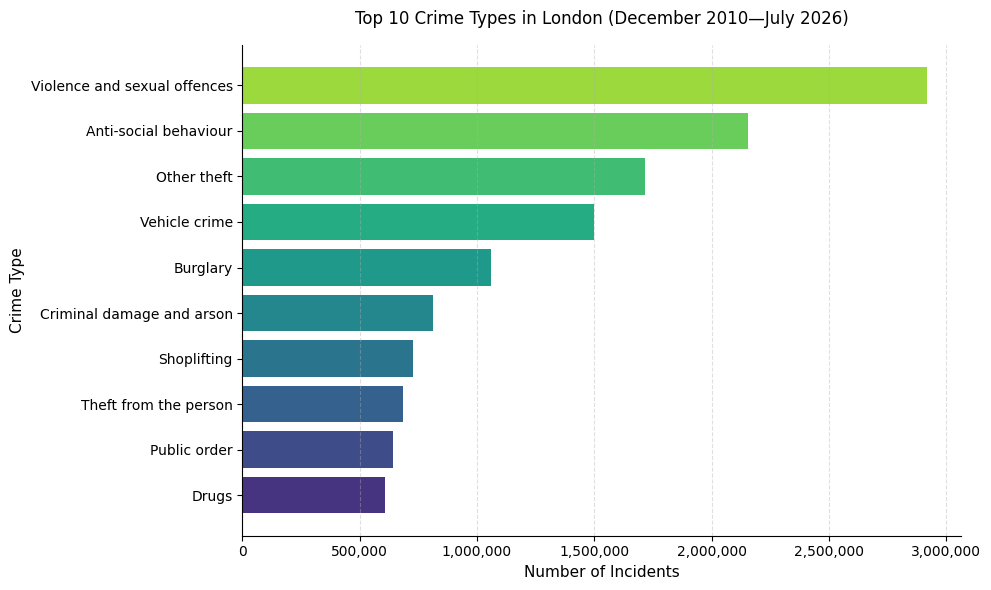

In [ ]:
# Load data
dataset_path = os.path.join(base_dir, 'clean_data', 'cleaned.csv')
df = pd.read_csv(dataset_path, usecols=["Crime type"])

# Count crime types
crime_counts = df["Crime type"].value_counts().head(10).sort_values()

# Colours
colors = [
    '#463480',
    '#3e4c8a',
    '#34618d',
    '#2b748e',
    '#24878e',
    '#1f998a',
    '#25ac82',
    '#40bd72',
    '#69cd5b',
    '#9bd93c'
    ]

# Plot & axes
fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    crime_counts.index,
    crime_counts.values,
    color=colors
)

# Print Data
for i in range(len(crime_counts.index)):
  print(crime_counts.index[i], crime_counts.values[i])

ax.set_title(
    "Top 10 Crime Types in London (December 2010\u2014July 2026)",
    fontsize=12,
    pad=15
)

ax.set_xlabel("Number of Incidents", fontsize=11)
ax.set_ylabel("Crime Type", fontsize=11)
ax.grid(axis="x", linestyle="--", alpha=0.4)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{int(x):,}'))

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()

plt.show()


### Crime Counts and Averages

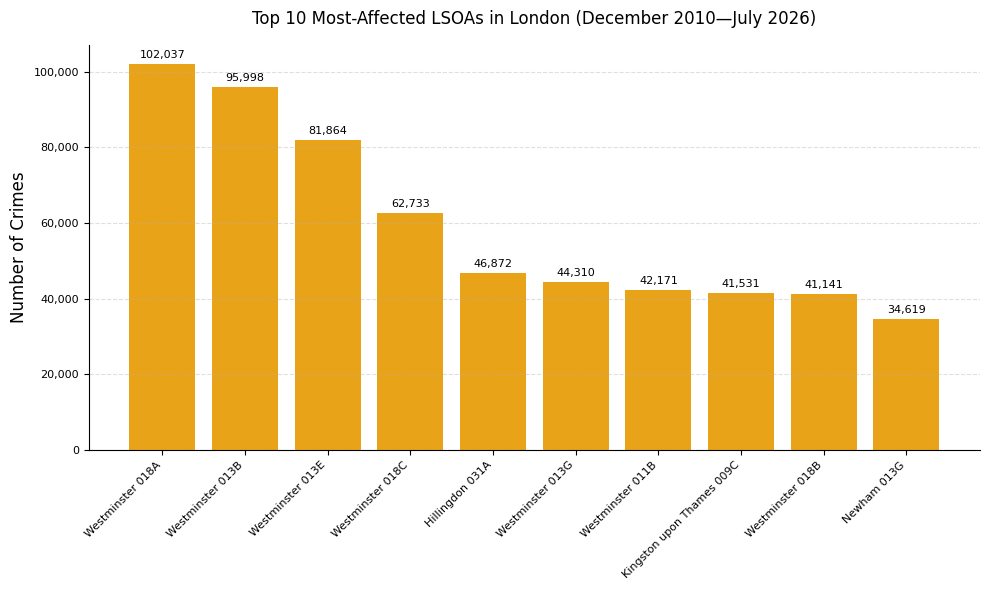

In [ ]:
# Load data
dataset_path = os.path.join(base_dir, 'clean_data', 'cleaned.csv')
df = pd.read_csv(dataset_path, usecols=["LSOA name"])

# Remove missing values
df = df.dropna()

# Top 10 LSOAs
lsoa_counts = df["LSOA name"].value_counts().sort_values(ascending=False).head(10)


# Plot
plt.figure(figsize=(10, 6))

bars = plt.bar(
    lsoa_counts.index,
    lsoa_counts.values,
    color="#e9a319"
)

# Set Labels and Grid
plt.xticks(rotation=45, ha='right', fontsize=8)
plt.yticks(fontsize=8)
plt.ylabel("Number of Crimes", fontsize=12)

ax = plt.gca()
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{int(x):,}'))

ax.bar_label(
    bars,
    labels=[f"{v:,}" for v in lsoa_counts.values],
    padding=3,
    fontsize=8
)

ax.set_title(
    "Top 10 Most-Affected LSOAs in London (December 2010\u2014July 2026)",
    fontsize=12,
    pad=15
)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.grid(axis="y", linestyle="--", alpha=0.4)


plt.tight_layout()
plt.show()

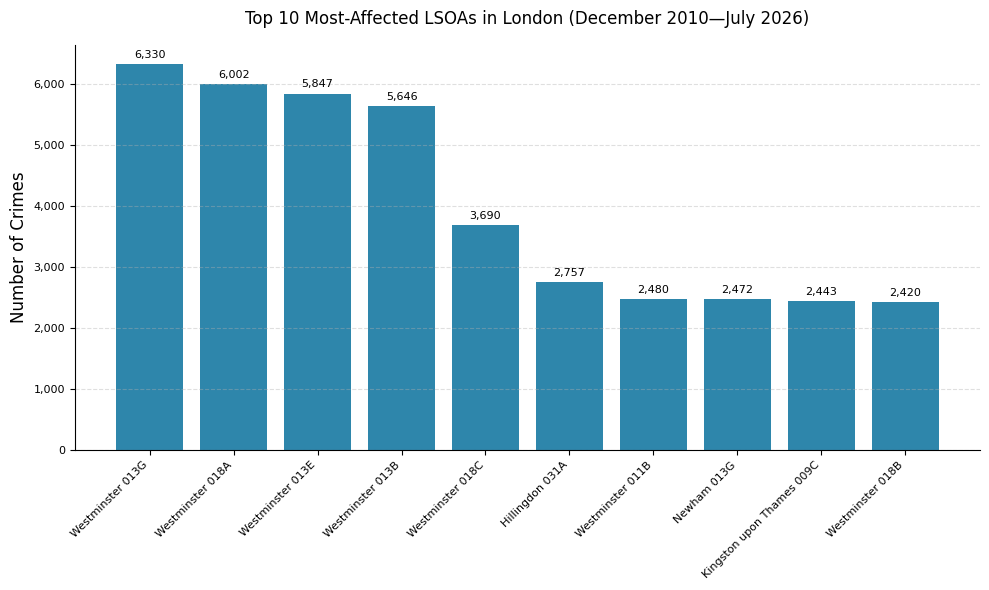

In [ ]:
# Load data
dataset_path = os.path.join(base_dir, 'clean_data', 'cleaned.csv')
df = pd.read_csv(dataset_path, usecols=["Month", "LSOA name"])

# Remove missing values
df = df.dropna()

# Convert Month
df["Month"] = pd.to_datetime(df["Month"])

# Extract Year
df["Year"] = df["Month"].dt.year

# Crime count per Year and LSOA
annual_counts = (
    df.groupby(["Year", "LSOA name"])
    .size()
    .reset_index(name="Crime Count")
)

# Average annual crime count
annual_average = (
    annual_counts.groupby("LSOA name")["Crime Count"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

# Plot
plt.figure(figsize=(10, 6))

bars = plt.bar(
    annual_average.index,
    annual_average.values,
    color="#2e86ab"
)

# Set Labels and Grid
plt.xticks(rotation=45, ha='right', fontsize=8)
plt.yticks(fontsize=8)
plt.ylabel("Number of Crimes", fontsize=12)

ax = plt.gca()
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{int(x):,}'))

ax.bar_label(
    bars,
    labels=[f"{int(v):,}" for v in annual_average.values],
    padding=3,
    fontsize=8
)

ax.set_title(
    "Top 10 Most-Affected LSOAs in London (December 2010\u2014July 2026)",
    fontsize=12,
    pad=15
)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.grid(axis="y", linestyle="--", alpha=0.4)


plt.tight_layout()
plt.show()

### Temporal Reported Crimes Trends

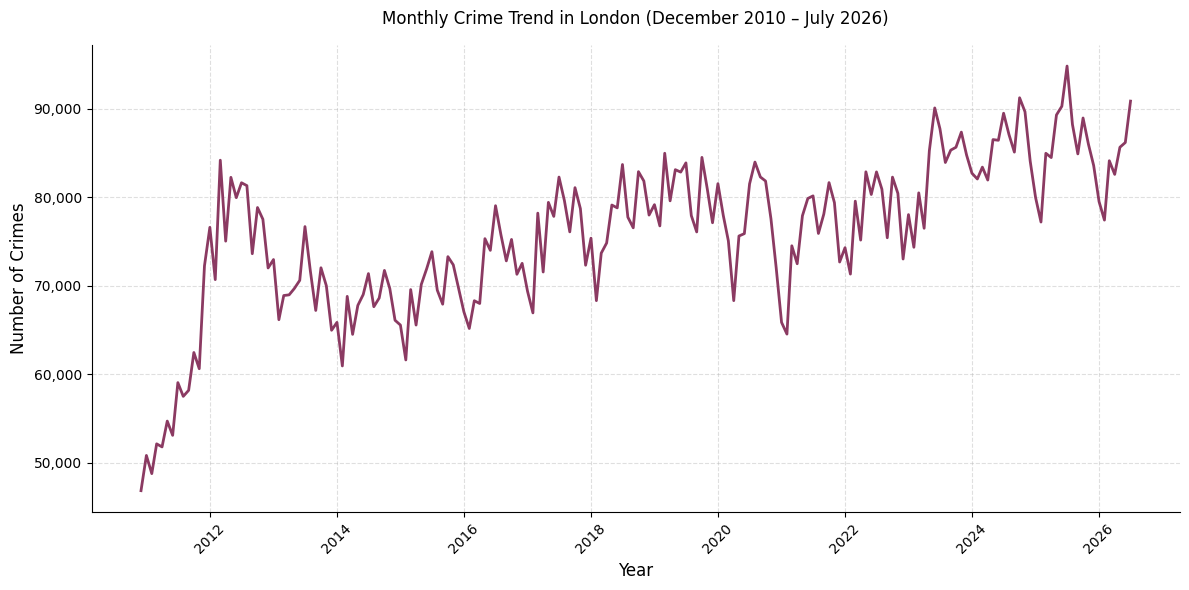

In [ ]:
# Load cleaned dataset
dataset_path = os.path.join(base_dir, 'clean_data', 'cleaned.csv')
df = pd.read_csv(
    dataset_path,
    usecols=["Month"]
)

# Remove missing months
df = df.dropna(subset=["Month"])

# Convert Month to datetime
df["Month"] = pd.to_datetime(
    df["Month"],
    format="%Y-%m"
)

# Count crimes for each month
monthly_counts = (
    df["Month"]
    .value_counts()
    .sort_index()
)

# Create figure
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_counts.index,
    monthly_counts.values,
    linewidth=2,
    color="#8b3a62"
)

# Title
plt.title(
    "Monthly Crime Trend in London (December 2010 – July 2026)",
    fontsize=12,
    pad=15
)

# Axis labels
plt.xlabel("Year", fontsize=12)
plt.ylabel("Number of Crimes", fontsize=12)

# X-axis
plt.xticks(rotation=45)

# Grid
plt.grid(
    linestyle="--",
    alpha=0.4
)

ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{int(x):,}'))

# Layout
plt.tight_layout()

# Display
plt.show()

### Seasonal Patterns

Jan 72801.6875
Feb 69390.6875
Mar 75691.9375
Apr 72589.9375
May 77805.3125
Jun 77958.4375
Jul 81200.25
Aug 77260.06666666667
Sep 75224.2
Oct 79592.13333333333
Nov 77568.93333333333
Dec 72636.875


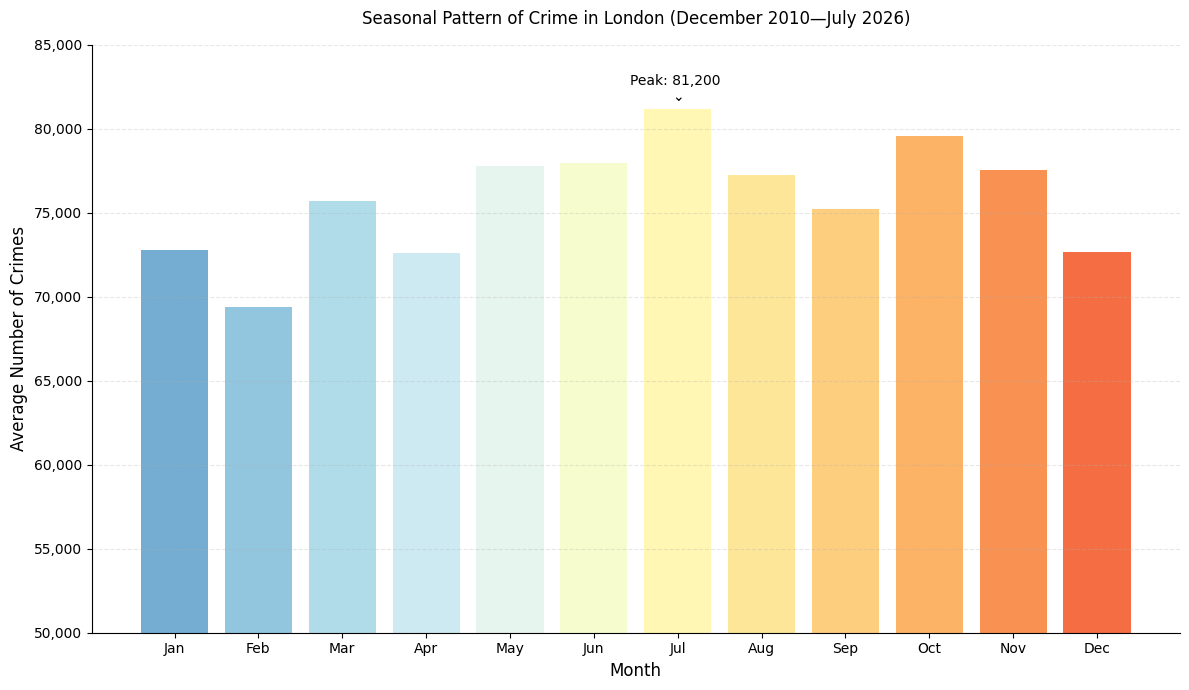

In [ ]:
# Load dataset
dataset_path = os.path.join(base_dir, 'clean_data', 'cleaned.csv')
df = pd.read_csv(dataset_path, usecols=["Month"])

# Remove missing values
df = df.dropna()

# Convert Month
df["Month"] = pd.to_datetime(df["Month"])

# Extract Year and Month number
df["Year"] = df["Month"].dt.year
df["Month_num"] = df["Month"].dt.month

# Monthly counts for each year
monthly_counts = (
    df.groupby(["Year", "Month_num"])
    .size()
    .reset_index(name="Crime Count")
)

# Average by calendar month
seasonal_counts = (
    monthly_counts.groupby("Month_num")["Crime Count"]
    .mean()
    .reindex(range(1, 13))
)

month_names = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

# 12 different colours
colors = [
    '#74add1',
    '#92c5de',
    '#b0dcea',
    '#cdeaf3',
    '#e6f5ed',
    '#f7fcce',
    '#fff7b3',
    '#fee699',
    '#fece7f',
    '#fdb366',
    '#f99153',
    '#f46d43'
]

# Plot
plt.figure(figsize=(12, 7))

bars = plt.bar(
    month_names,
    seasonal_counts.values,
    color=colors
)

# Print Values

for i in range(len(month_names)):
  print(month_names[i], seasonal_counts.values[i])

plt.title(
    "Seasonal Pattern of Crime in London (December 2010\u2014July 2026)",
    fontsize=12,
    pad=15
)

# Set axes and grid
plt.xlabel("Month", fontsize=12)
plt.ylabel("Average Number of Crimes", fontsize=12)

ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{int(x):,}'))
ax.set_ylim(50000,85000)

labels = [f"Peak: {int(v):,} \n\u2304" for v in seasonal_counts.values]
labels = [labels[i] if i==6 else "" for i in range(12)]

ax.bar_label(
    bars,
    labels=labels,
    padding=3,
    fontsize=10
)


plt.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()

plt.show()

## Model Visualisations

### Feature Importance

Month 0.05182179789824547
Year 0.1418674989327175
Anti-social behaviour 0.016491542688493
Bicycle theft 0.00047651761467922416
Burglary 0.003216684552181036
Criminal damage and arson 0.0017812866912736856
Drugs 0.0018595292360930249
Other crime 0.008043730524065013
Other theft 0.014131879919141228
Possession of weapons 0.0013119919500987549
Public disorder and weapons 0.001092874074230952
Public order 0.0010424858880160141
Robbery 0.0016417441030328822
Shoplifting 0.011233380678458563
Theft from the person 0.0024567451723062324
Vehicle crime 0.00770669563598638
Violence and sexual offences 0.020842676060425676
Violent crime 0.003571519057102905
x 0.43039819275561364
y 0.2790112265678388


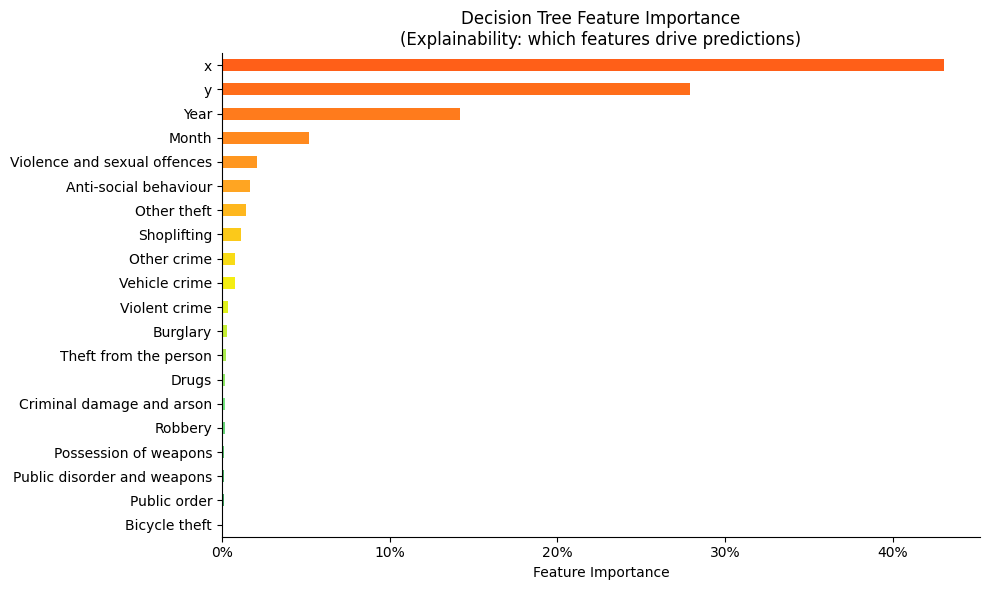

In [ ]:
# Read columns from first line of CSV
dataset_path = os.path.join(base_dir, 'clean_data', 'encoded.csv')

# Get the columns
columns = pd.read_csv(dataset_path, nrows=1)
columns = columns.drop(columns=["Count"])
columns = columns.columns

model_path = os.path.join(base_dir, 'models', 'tree.pkl')

# Load model
with open(model_path, "rb") as f:
  model = pickle.load(f)

# Set colour scheme
colours = [
    "#2E8B57",
    "#3C9D5F",
    "#4AAF67",
    "#58C16F",
    "#66D377",
    "#74E57F",
    "#8FE866",
    "#AAEB4D",
    "#C5EE34",
    "#E0F11B",
    "#F4ED12",
    "#F8DB16",
    "#FBC91A",
    "#FEB71E",
    "#FFA522",
    "#FF9720",
    "#FF891E",
    "#FF7B1C",
    "#FF6D1A",
    "#FF5F18"
]

# Get feature importance
importance = pd.Series(
    model.feature_importances_,
    index=columns
).sort_values(ascending=True)

for i in range(len(columns)):
  print(columns[i], model.feature_importances_[i])

# Plot
plt.figure(figsize=(10, 6))
importance.plot(kind="barh", color=colours)
plt.title("Decision Tree Feature Importance\n(Explainability: which features drive predictions)")

# Set axes and grid
plt.xlabel("Feature Importance")
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{int(x*100):,}%'))

plt.tight_layout()
plt.show()


### Predicted v Actual

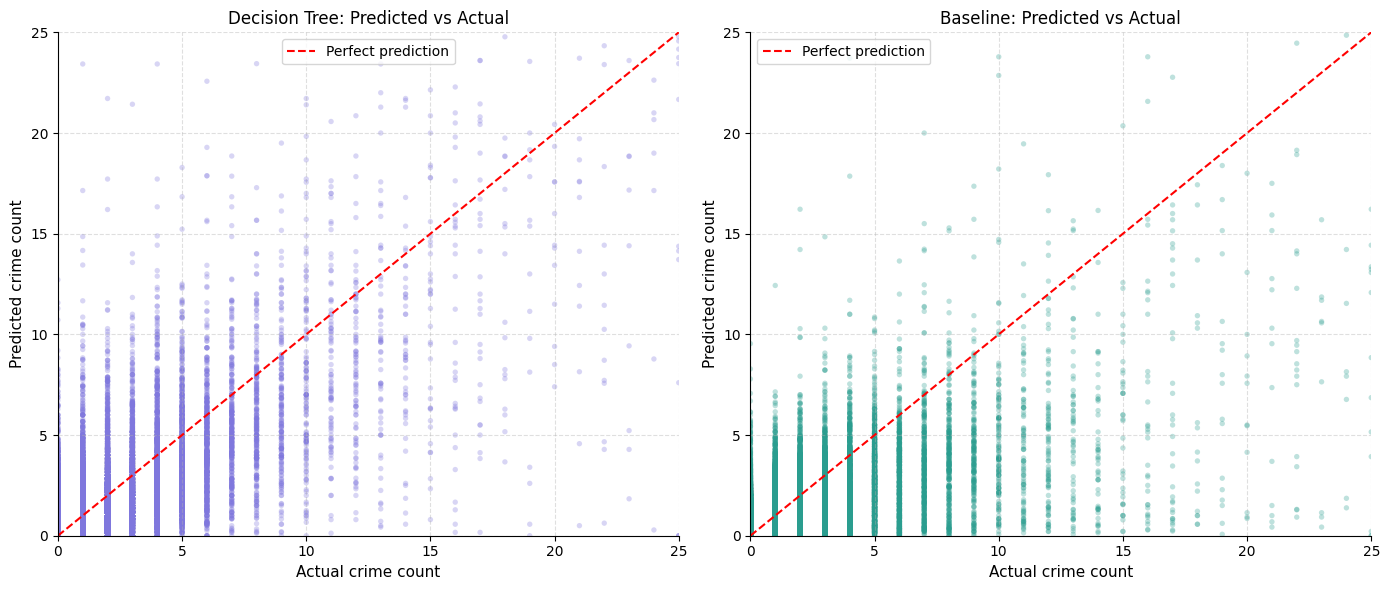

In [ ]:
#Load Dataset
dataset_path = os.path.join(base_dir, 'clean_data', 'encoded.csv')
df = pd.read_csv(dataset_path)

# Only load test
test = df[(df['Year'] > 2024) | ((df['Month'] > 7) & (df['Year'] == 2024))].reset_index(drop=True)
del df
gc.collect()

# Take 200k sample indeces, to be used for both datasets
sample_idx = test.sample(n=200000, random_state=42).index
sample = test.loc[sample_idx]

del test
gc.collect()

# Load tree model and create predicted values
model_path = os.path.join(base_dir, 'models', 'tree.pkl')

with open(model_path, "rb") as f:
  model = pickle.load(f)

input_x = sample.drop(columns=['Count'])
tree_actual_y = sample['Count']
tree_pred_y = model.predict(input_x)

del sample
gc.collect()

# Load naive baseline and sample the same indeces
baseline_path = os.path.join(base_dir, 'models', 'naive_baseline.csv')
df = pd.read_csv(baseline_path)
sample = df.loc[sample_idx]

del df
gc.collect()

# Create baseline actual v predicted
baseline_actual_y = sample['Count']
baseline_pred_y = sample['baseline_pred']

# we are only interested in smaller values, ignoring outliers
max_val = 25

# Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Decision Tree
ax = axes[0]
ax.scatter(tree_actual_y, tree_pred_y,
           alpha=0.3, s=15, color='#7F77DD', edgecolor='none')

ax.plot([0, max_val], [0, max_val], 'r--', lw=1.5, label='Perfect prediction')
ax.set_xlabel('Actual crime count', fontsize=11)
ax.set_ylabel('Predicted crime count', fontsize=11)
ax.set_title('Decision Tree: Predicted vs Actual', fontsize=12)
ax.legend()
ax.grid(linestyle='--', alpha=0.4)
ax.set_xlim(0,max_val)
ax.set_ylim(0,max_val)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Baseline
ax = axes[1]
ax.scatter(baseline_actual_y, baseline_pred_y,
           alpha=0.3, s=15, color='#2A9D8F', edgecolor='none')
ax.plot([0, max_val], [0, max_val], 'r--', lw=1.5, label='Perfect prediction')
ax.set_xlabel('Actual crime count', fontsize=11)
ax.set_ylabel('Predicted crime count', fontsize=11)
ax.set_title('Baseline: Predicted vs Actual', fontsize=12)
ax.legend()
ax.grid(linestyle='--', alpha=0.4)
ax.set_xlim(0,max_val)
ax.set_ylim(0,max_val)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)


plt.tight_layout()
plt.show()


### Error Distributions

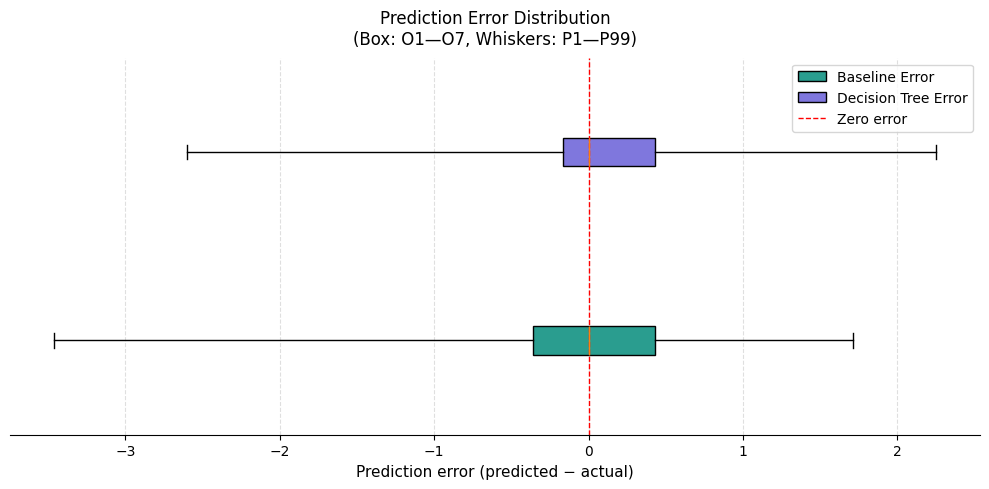

In [ ]:
# Load data
dataset_path = os.path.join(base_dir, 'clean_data', 'encoded.csv')
df = pd.read_csv(dataset_path)

# Only keep test
test = df[(df['Year'] > 2024) | ((df['Month'] > 7) & (df['Year'] == 2024))].reset_index(drop=True)

del df
gc.collect()

# Load tree model
model_path = os.path.join(base_dir, 'models', 'tree.pkl')

with open(model_path, "rb") as f:
  model = pickle.load(f)

# Keep actual y and use model to get predicted y
input_x = test.drop(columns=['Count'])
tree_actual_y = test['Count']
tree_pred_y = model.predict(input_x)

del test
del input_x
gc.collect()

# calculate decision tree errors
dt_error = tree_pred_y - tree_actual_y

del tree_pred_y
del tree_actual_y
gc.collect()

# Load baseline model and calculate errors
baseline_path = os.path.join(base_dir, 'models', 'naive_baseline.csv')
df = pd.read_csv(baseline_path)

baseline_error = df['baseline_pred'] - df['Count']

del df
gc.collect()


# Cleare a plot
fig, ax = plt.subplots(figsize=(10, 5))

# Create nonstandard boxplot values
stats = []
for data in [baseline_error, dt_error]:
  stats.append({
          'med': np.percentile(data, 50),
          'q1': np.percentile(data, 7.5),
          'q3': np.percentile(data, 92.5),
          'whislo': np.percentile(data, 1),
          'whishi': np.percentile(data, 99),
          'fliers': []
        })

# Plot
box = ax.bxp(stats, showfliers=False, label=["Baseline Error",
    "Decision Tree Error"], patch_artist=True, vert=False)


# Set colours
colors = ["#2A9D8F", "#7F77DD"]
for patch, color in zip(box["boxes"], colors):
    patch.set_facecolor(color)

# Edit axes
ax.axvline(x=0, color='red', linestyle='--', linewidth=1, label='Zero error')
ax.set_xlabel('Prediction error (predicted − actual)', fontsize=11)
ax.set_title('Prediction Error Distribution\n(Box: O1\u2014O7, Whiskers: P1\u2014P99)', fontsize=12, pad=10)
ax.legend()
ax.grid(axis='x', linestyle='--', alpha=0.4)
ax.yaxis.set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)


plt.tight_layout()
plt.show()